In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.impute import SimpleImputer

In [86]:
# Load the data
data = pd.read_csv("/content/Titanic-Dataset.csv")

In [87]:
data

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


Display basic info about the dataset

In [88]:
data.shape

(891, 12)

In [89]:
# data.size make the number of rows * number of columns (891 * 12)
data.size

10692

In [90]:
print("First 20 rows:")
data.head(20)

First 20 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [91]:
print("Last 20 rows:")
data.tail(20)

Last 20 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
871,872,1,1,"Beckwith, Mrs. Richard Leonard (Sallie Monypeny)",female,47.0,1,1,11751,52.5542,D35,S
872,873,0,1,"Carlsson, Mr. Frans Olof",male,33.0,0,0,695,5.0000,B51 B53 B55,S
873,874,0,3,"Vander Cruyssen, Mr. Victor",male,47.0,0,0,345765,9.0000,NaN,S
874,875,1,2,"Abelson, Mrs. Samuel (Hannah Wizosky)",female,28.0,1,0,P/PP 3381,24.0000,NaN,C
875,876,1,3,"Najib, Miss. Adele Kiamie ""Jane""",female,15.0,0,0,2667,7.2250,NaN,C
876,877,0,3,"Gustafsson, Mr. Alfred Ossian",male,20.0,0,0,7534,9.8458,NaN,S
877,878,0,3,"Petroff, Mr. Nedelio",male,19.0,0,0,349212,7.8958,NaN,S
878,879,0,3,"Laleff, Mr. Kristo",male,NaN,0,0,349217,7.8958,NaN,S
879,880,1,1,"Potter, Mrs. Thomas Jr (Lily Alexenia Wilson)",female,56.0,0,1,11767,83.1583,C50,C
880,881,1,2,"Shelley, Mrs. William (Imanita Parrish Hall)",female,25.0,0,1,230433,26.0000,NaN,S


In [92]:
print("Dataset Info:")
data.info()

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [93]:
print("Summary Statistics:")
data.describe()

Summary Statistics:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [94]:
data.columns = data.columns.str.lower()

In [95]:
data.describe()[["age"]]

,age
count,714.000000
mean,29.699118
std,14.526497
min,0.420000
25%,20.125000
50%,28.000000
75%,38.000000
max,80.000000


In [96]:
data[data['age'] == 0.42]

,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
803,804,1,3,"Thomas, Master. Assad Alexander",male,0.42,0,1,2625,8.5167,NaN,C


In [97]:
data.describe(exclude= "number")

,name,sex,ticket,cabin,embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


In [98]:
print("Missing values in each column:")
data.isnull().sum()

Missing values in each column:


,0
passengerid,0
survived,0
pclass,0
name,0
sex,0
age,177
sibsp,0
parch,0
ticket,0
fare,0


In [99]:
data['age'] = data.groupby(['pclass', 'sex'])['age'].transform(lambda x: x.fillna(x.median()))

In [100]:
data.drop('cabin', axis=1, inplace= True)

In [101]:
data['embarked'].fillna(data['embarked'].mode()[0], inplace=True)

/tmp/ipython-input-879075962.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['embarked'].fillna(data['embarked'].mode()[0], inplace=True)


In [102]:
print("Missing values after handling:")
data.isnull().sum()

Missing values after handling:


,0
passengerid,0
survived,0
pclass,0
name,0
sex,0
age,0
sibsp,0
parch,0
ticket,0
fare,0


In [103]:
for i in data.columns:
  print(f"{i}: {data[i].nunique()} unique by {data[i].nunique()/data.shape[0]*100}")

passengerid: 891 unique by 100.0
survived: 2 unique by 0.22446689113355783
pclass: 3 unique by 0.33670033670033667
name: 891 unique by 100.0
sex: 2 unique by 0.22446689113355783
age: 89 unique by 9.988776655443322
sibsp: 7 unique by 0.7856341189674524
parch: 7 unique by 0.7856341189674524
ticket: 681 unique by 76.43097643097643
fare: 248 unique by 27.83389450056117
embarked: 3 unique by 0.33670033670033667


/tmp/ipython-input-3863366437.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data = data, x=i, palette= "pastel", edgecolor = "black")


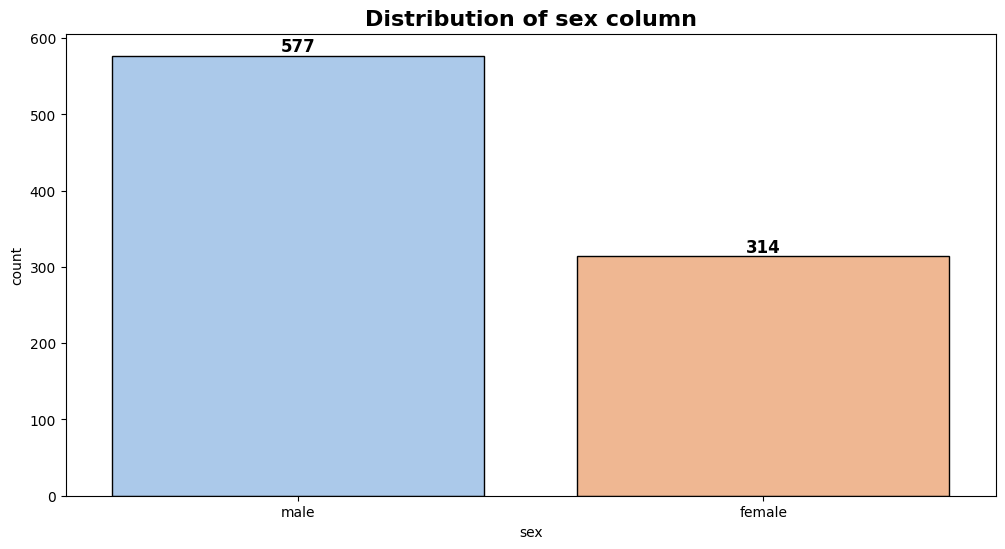

/tmp/ipython-input-3863366437.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data = data, x=i, palette= "pastel", edgecolor = "black")


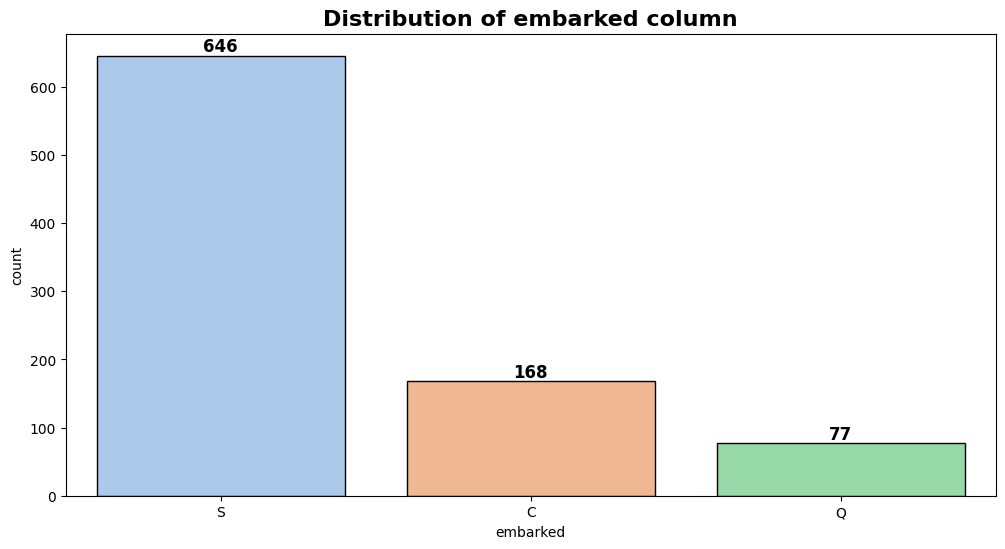

In [104]:
for i in data.select_dtypes(include="object").columns:
  if i not in ["name", "ticket", "cabin"]:
    plt.figure(figsize=(12, 6))
    ax = sns.countplot(data = data, x=i, palette= "pastel", edgecolor = "black")
    plt.title(f"Distribution of {i} column", fontsize = 16, fontweight= "bold")
    for i in ax.containers:
      ax.bar_label(i, fontsize = 12, fontweight= "bold")
    plt.show()


/tmp/ipython-input-1321975500.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data = data, x=i, palette= "pastel", edgecolor = "black")


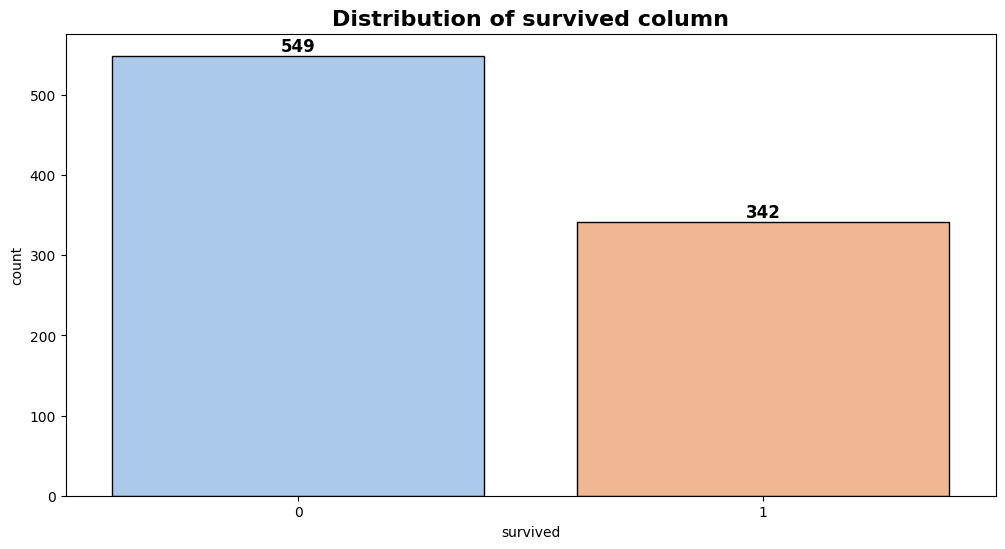

/tmp/ipython-input-1321975500.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data = data, x=i, palette= "pastel", edgecolor = "black")


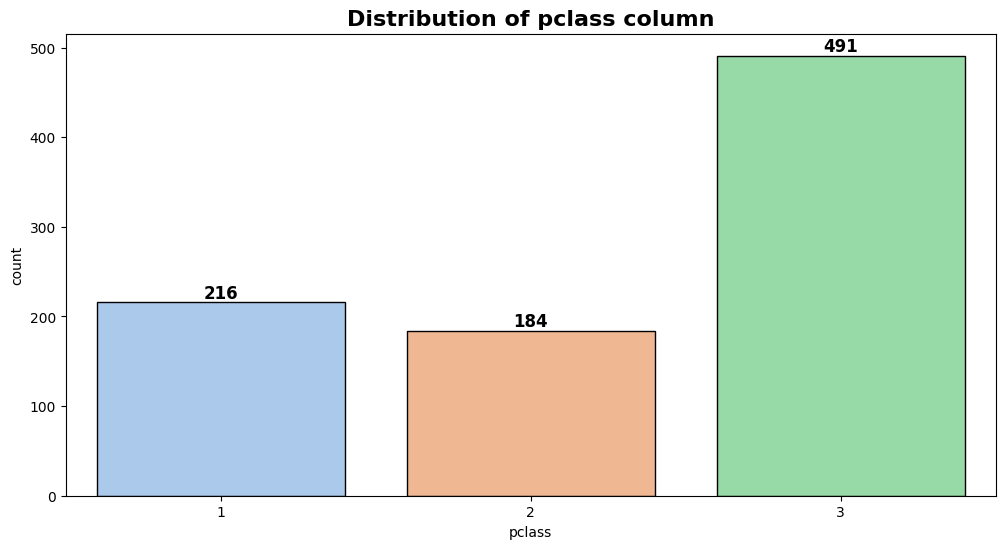

/tmp/ipython-input-1321975500.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data = data, x=i, palette= "pastel", edgecolor = "black")


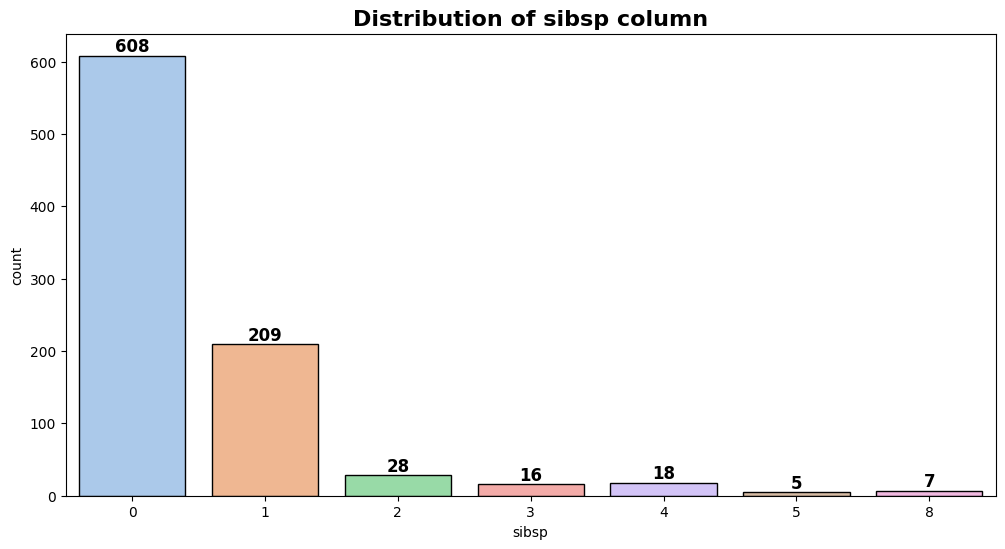

/tmp/ipython-input-1321975500.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data = data, x=i, palette= "pastel", edgecolor = "black")


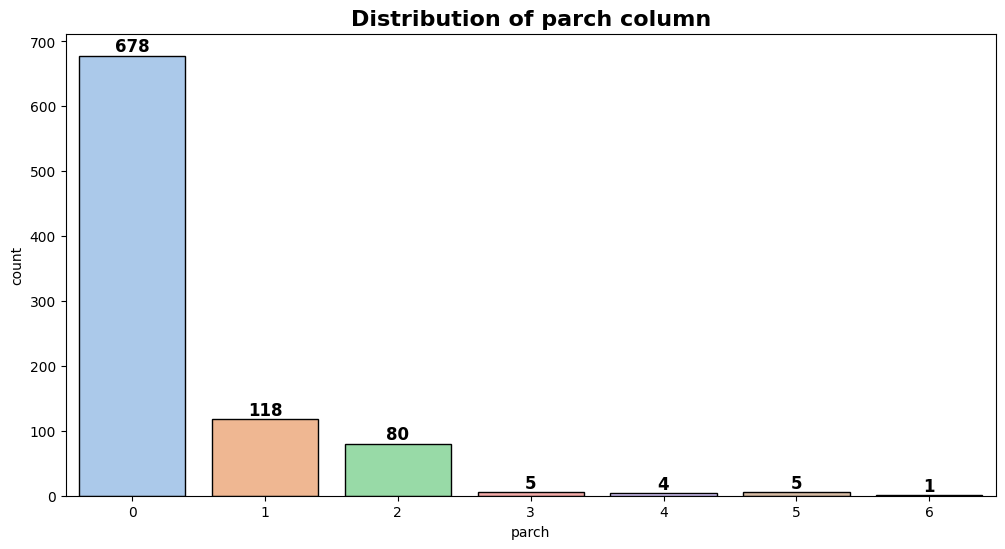

In [105]:
for i in data.select_dtypes(include="int").columns:
  if i not in ["passengerid"]:
    plt.figure(figsize=(12, 6))
    ax = sns.countplot(data = data, x=i, palette= "pastel", edgecolor = "black")
    plt.title(f"Distribution of {i} column", fontsize = 16, fontweight= "bold")
    for i in ax.containers:
      ax.bar_label(i, fontsize = 12, fontweight= "bold")
    plt.show()


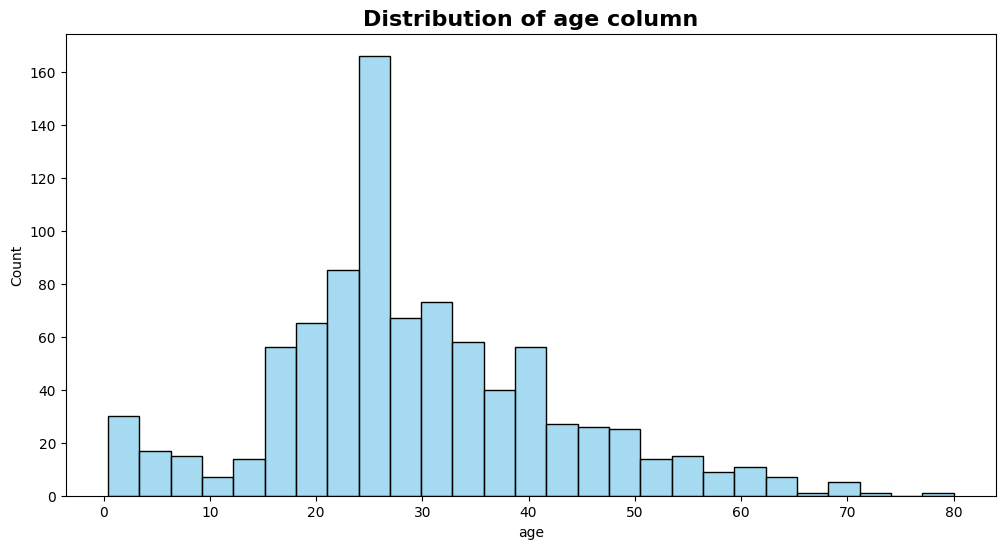

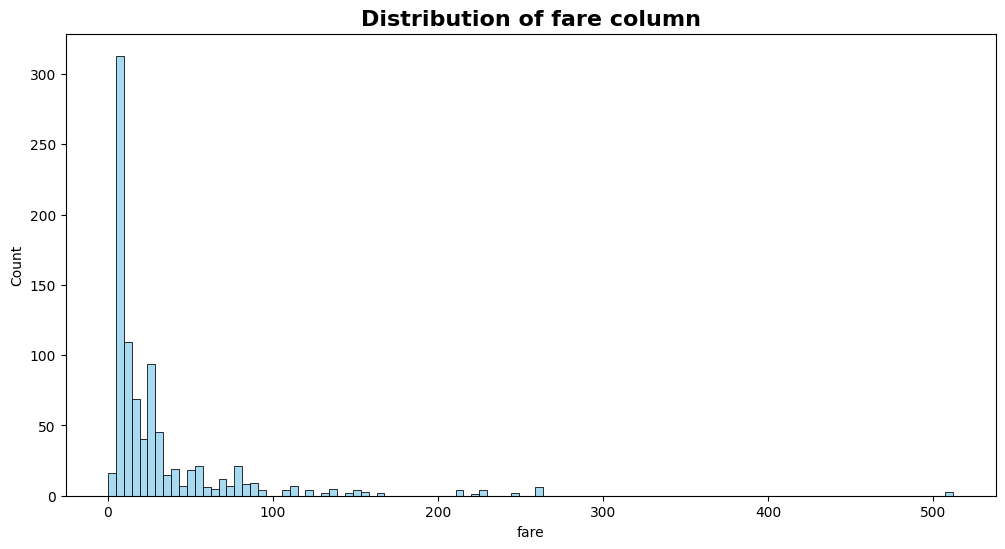

In [106]:
for i in data.select_dtypes(include="float").columns:
    plt.figure(figsize=(12, 6))
    sns.histplot(data[i], color= "skyblue", edgecolor = "black")
    plt.title(f"Distribution of {i} column", fontsize = 16, fontweight= "bold")
    plt.show()


In [107]:
data_sur = data.groupby("survived")
data_sur.get_group(0)

,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S
5,6,0,3,"Moran, Mr. James",male,25.0,0,0,330877,8.4583,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,S
...,...,...,...,...,...,...,...,...,...,...,...
884,885,0,3,"Sutehall, Mr. Henry Jr",male,25.0,0,0,SOTON/OQ 392076,7.0500,S
885,886,0,3,"Rice, Mrs. William (Margaret Norton)",female,39.0,0,5,382652,29.1250,Q
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,21.5,1,2,W./C. 6607,23.4500,S


In [108]:
data_sur = data.groupby("survived")["pclass"].value_counts()
data_sur.index

MultiIndex([(0, 3),
            (0, 2),
            (0, 1),
            (1, 1),
            (1, 3),
            (1, 2)],
           names=['survived', 'pclass'])

In [109]:
data_sur = data.groupby("survived")["pclass"].value_counts()
data_sur.index.levels[0]

Index([0, 1], dtype='int64', name='survived')

In [110]:
data_sur = data.groupby("survived")["pclass"].value_counts()
data_sur.index.levels[1]

Index([1, 2, 3], dtype='int64', name='pclass')

In [111]:
data["pclass"].value_counts()

,count
pclass,
3,491
1,216
2,184


<Axes: ylabel='count'>

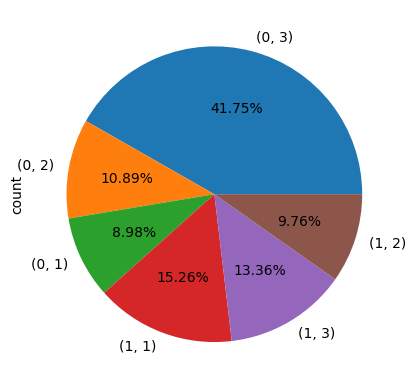

In [112]:
data_sur = data.groupby("survived")["pclass"].value_counts().plot.pie(autopct = "%.2f%%")
data_sur

In [113]:
data.drop('passengerid', axis=1, inplace= True)

In [114]:
data.drop('name', axis=1, inplace= True)

In [115]:
data.drop('ticket', axis=1, inplace= True)

In [116]:
data.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked'],
      dtype='object')

In [117]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    object 
 3   age       891 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  891 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [118]:
# Family size feature
data['FamilySize'] = data['sibsp'] + data['parch'] + 1

In [119]:
# Is alone feature
data['IsAlone'] = 0
data.loc[data['FamilySize'] == 1, 'IsAlone'] = 1

In [120]:
# Age groups
data['AgeGroup'] = pd.cut(data['age'], bins = [0, 12, 18, 35, 60, 100], labels= ['child', 'teen', 'adult', 'middle', 'senior'])

In [121]:
data['FareGroup'] = pd.qcut(data['fare'], 4, labels=['low', 'medium', 'high', 'very high'])

In [122]:
print("Updated dataset after feature engineering:")
data.head()

Updated dataset after feature engineering:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,FamilySize,IsAlone,AgeGroup,FareGroup
0,0,3,male,22.0,1,0,7.2500,S,2,0,adult,low
1,1,1,female,38.0,1,0,71.2833,C,2,0,middle,very high
2,1,3,female,26.0,0,0,7.9250,S,1,1,adult,medium
3,1,1,female,35.0,1,0,53.1000,S,2,0,adult,very high
4,0,3,male,35.0,0,0,8.0500,S,1,1,adult,medium


In [124]:
# Encode categorical variables
label_encoders = {}
categorical_cols = ['sex', 'embarked', 'AgeGroup', 'FareGroup']

for col in categorical_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col].astype(str))
    label_encoders[col] = le

# Separate features and target
X = data.drop('survived', axis=1)
y = data['survived']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale numerical features
scaler = StandardScaler()
numerical_cols = ['age', 'fare', 'sibsp', 'parch', 'FamilySize']
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (712, 11)
Testing set shape: (179, 11)


In [125]:
# Initialize and train the model
logreg = LogisticRegression(random_state=42, max_iter=1000)
logreg.fit(X_train, y_train)

# Make predictions
y_pred = logreg.predict(X_test)
y_pred_proba = logreg.predict_proba(X_test)[:, 1]  # Probability of survival

print("Model training completed.")

Model training completed.


Model Accuracy: 81.00558659217877


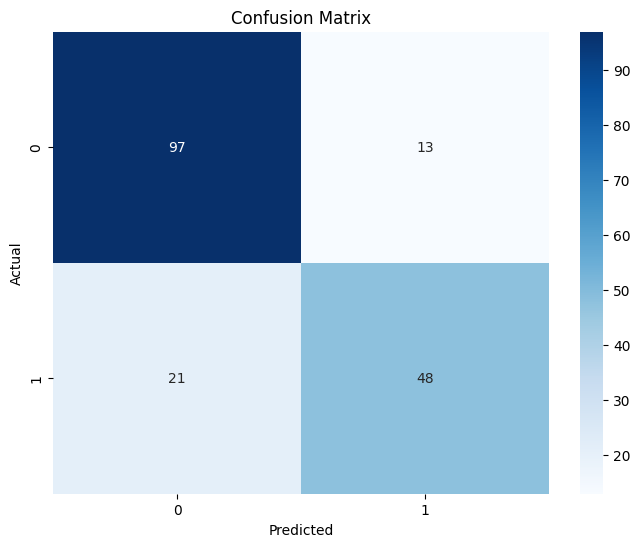


Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.79      0.70      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179


Feature Importance:
       Feature  Importance
5         fare    0.091908
10   FareGroup   -0.022856
4        parch   -0.043779
9     AgeGroup   -0.056091
6     embarked   -0.182820
7   FamilySize   -0.211918
3        sibsp   -0.282878
8      IsAlone   -0.524365
2          age   -0.537564
0       pclass   -1.121472
1          sex   -2.511953


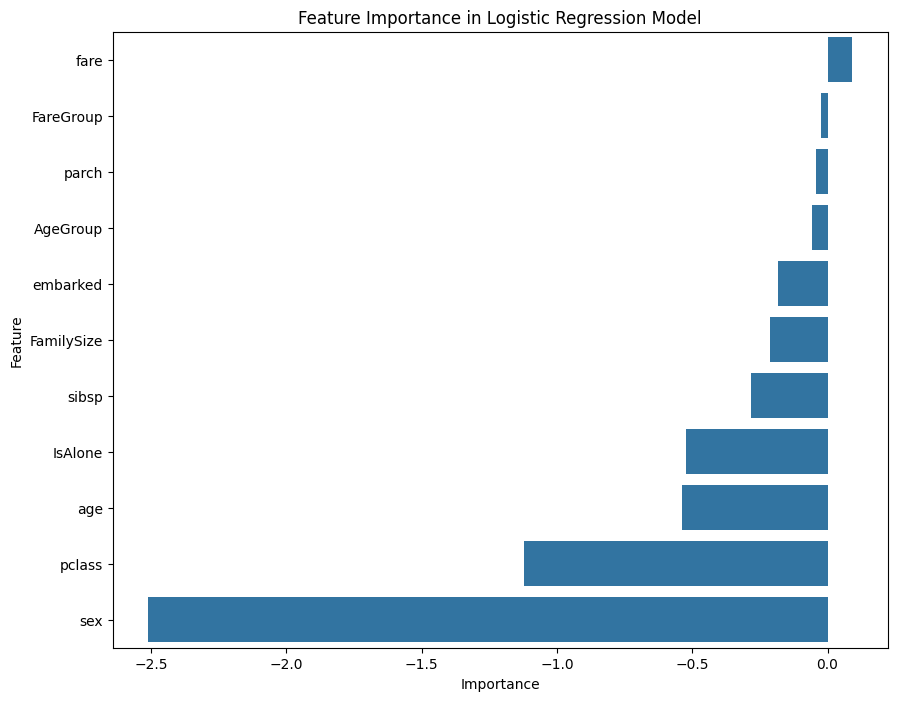

In [129]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': logreg.coef_[0]
}).sort_values('Importance', ascending=False)

print("\nFeature Importance:")
print(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance)
plt.title('Feature Importance in Logistic Regression Model')
plt.show()